# Day 37 Classification using Support Vector Machine with Naive Bayes

Di notebook ini kita berkenalan dengan dua algoritma klasifikasi klasik yang sangat populer: **Support Vector Machine (SVM)** dan **Naive Bayes**. Keduanya bekerja dengan prinsip yang sangat berbeda, dan kita akan membandingkan performa mereka pada masalah nyata:

memprediksi apakah sebuah anggur (wine) tergolong **berkualitas baik** atau tidak.

> 🎯 **Tujuan Pembelajaran**
> - Memahami ide dasar **SVM** (mencari garis/bidang pemisah terbaik) & **Naive Bayes** (probabilitas).
> - Mengubah target numerik (`quality`) menjadi **target biner** (`quality_baik`).
> - Memahami kenapa **scaling** penting untuk SVM tapi tidak untuk Naive Bayes.
> - Melatih `SVC` dan `GaussianNB`, lalu **membandingkan** keduanya.
> - Membaca **confusion matrix** dan **classification_report**.

## About Dataset

Saya memakai **Red Wine Quality** — data hasil uji kimia 1.599 sampel anggur merah Portugal, beserta skor kualitas (0–10) yang diberikan penguji ahli.

- **Sumber:** [Kaggle — uciml/red-wine-quality-cortez-et-al-2009](https://www.kaggle.com/datasets/uciml/red-wine-quality-cortez-et-al-2009)
- **Jumlah data:** 1.599 baris × 12 kolom

| Kolom | Arti |
|-------|------|
| `fixed acidity`, `volatile acidity`, `citric acid` | Kandungan asam |
| `residual sugar` | Sisa gula |
| `chlorides`, `free sulfur dioxide`, `total sulfur dioxide` | Garam & sulfur |
| `density`, `pH`, `sulphates` | Sifat fisik/kimia |
| `alcohol` | Kadar alkohol (%) |
| `quality` | Skor kualitas 0–10 (kita ubah jadi target biner) |

## Import Library

- **pandas / numpy** → olah data tabel & angka.
- **matplotlib / seaborn** → visualisasi.
- **sklearn** → `train_test_split` (bagi data), `StandardScaler` (scaling), `SVC` (SVM),
  `GaussianNB` (Naive Bayes), dan metrik evaluasi klasifikasi.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#Import pemisah data latih dengan data testing
from sklearn.model_selection import train_test_split

#Import pengskalaan untuk data latih dan model
from sklearn.preprocessing import StandardScaler

#Import Model Algorithm
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

#Import Metric untuk Model
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay,accuracy_score

## Import Dataset

In [3]:
!pip install kaggle
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d uciml/red-wine-quality-cortez-et-al-2009
!unzip red-wine-quality-cortez-et-al-2009.zip

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/uciml/red-wine-quality-cortez-et-al-2009
License(s): DbCL-1.0
100% 25.6k/25.6k [00:00<00:00, 28.1MB/s]

Archive:  red-wine-quality-cortez-et-al-2009.zip
  inflating: winequality-red.csv     


## Eksplorasi Awal Dataset

In [6]:
df = pd.read_csv('winequality-red.csv')
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


In [7]:
df.info()

print(f'Jumlah data: {df.shape[0]}')
print(f'Jumlah kolom: {df.shape[1]}')
print(f'Jumlah data null: {df.isnull().sum().sum()}')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB
Jumlah data: 1599
Jumlah kolom: 12
Jumlah data null: 0


**Interpretasi :**
  -  a.  Semua fitur berupa angka hasil uji laboratorium. Kolom terakhir, `quality`, adalah skor penilaian ahli yang akan menjadi dasar target kita.
  -  b. Data berisi 1.599 baris × 12 kolom dan **tidak ada nilai hilang** — siap diolah.


In [9]:
df['quality'].value_counts().sort_index()

,count
quality,
3,10
4,53
5,681
6,638
7,199
8,18


**Interpretasi :**

  -  a.  Skor kualitas mayoritas di 5 dan 6. Skor tinggi (7 ke atas) cukup jarang.
  
Ini sudah memberi petunjuk bahwa kelas "anggur baik" akan menjadi **kelas minoritas**.


## Creating Binary Target ( Good Quality )

In [10]:
df['good_quality'] = (df['quality'] >= 7).astype(int)

print(df['good_quality'].value_counts())

print("\nProporsi anggur baik: {:.1%}".format(df['good_quality'].mean()))

good_quality
0    1382
1     217
Name: count, dtype: int64

Proporsi anggur baik: 13.6%


**Interpretasi :**
  -  A. Hanya sekitar **13,6%** anggur tergolong baik. Datanya **tidak seimbang**,
  -  B. jadi nanti tidak boleh hanya melihat akurasi — Lihat juga precision & recall lebih informatif.

## Exploratory Data Analysis and Visualization

### a) Sebaran Kelas Target

/tmp/ipykernel_917/4233265668.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='good_quality', palette='pastel')


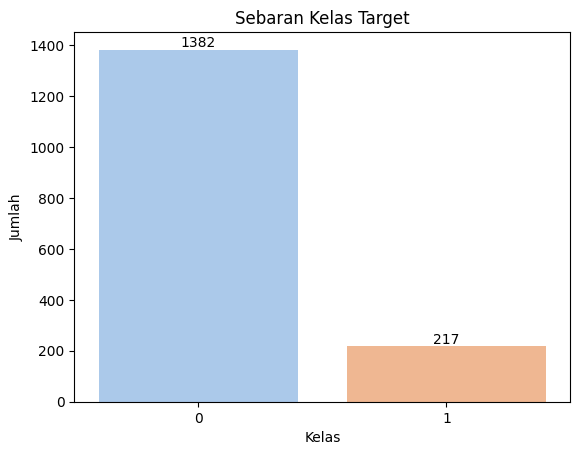

In [21]:
sns.countplot(data=df, x='good_quality', palette='pastel')
plt.title('Sebaran Kelas Target')
plt.xlabel('Kelas')
plt.ylabel('Jumlah')
for i in range(2):
    plt.text(i, df['good_quality'].value_counts()[i], df['good_quality'].value_counts()[i], ha='center', va='bottom')
plt.show()

**Interpretasi :**
  -  a. Terlihat Jelas kelas `0` lebih banyak daripada anggur dengan kualitas baik `1`


### b) Kadar Alkohol per Kelas ( Boxplot )

/tmp/ipykernel_917/3380619782.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='good_quality', y='alcohol', palette='pastel')


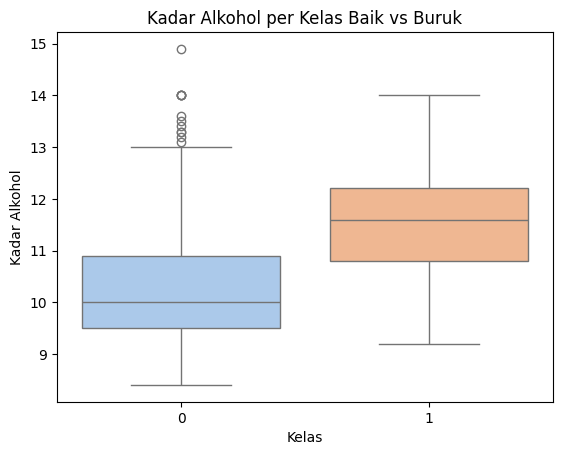

In [23]:
sns.boxplot(data=df, x='good_quality', y='alcohol', palette='pastel')
plt.title('Kadar Alkohol per Kelas Baik vs Buruk')
plt.xlabel('Kelas')
plt.ylabel('Kadar Alkohol')
plt.show()

**Interpretasi :**
  -  a. Pada kelas `1` atau baik, kadar alkoholnya lebih tinggi dibanding kualitas yang tidak baik
  -  b. Bisa di Indikasikan sebagai salah satu fitur yang berpengaruh

### c) Heatmap Correlation

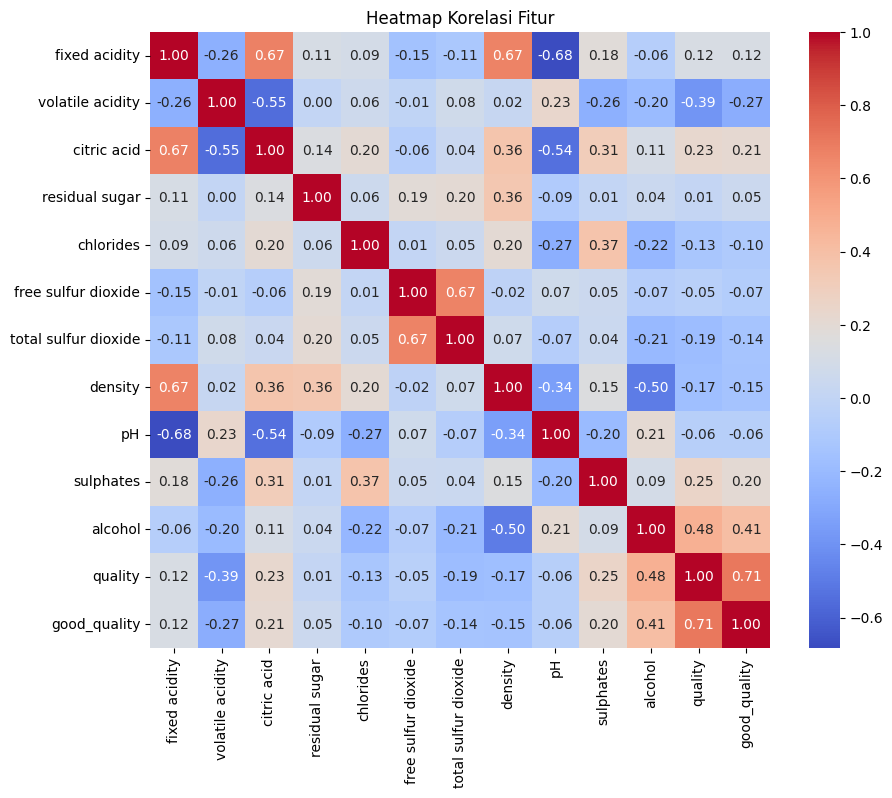

In [26]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Heatmap Korelasi Fitur')
plt.show()

**Interpretasi :**
  -  a.  `alcohol` punya korelasi positif terkuat dengan `quality`,
  -  b. sedangkan `volatile acidity` berkorelasi negatif (semakin asam mudah menguap, kualitas cenderung turun).

## Preprocessing ( Split & Scalling )

Pisahkan fitur (`X`) dan target (`y`), lalu bagi menjadi data latih & uji.

Karena kelas tidak seimbang, kita pakai `stratify=y` agar proporsi kelas tetap terjaga.

**Kenapa scaling?**
- SVM menghitung jarak antar titik. Bila satu fitur punya skala sangat besar (mis. `total sulfur dioxide` ratusan) dan lainnya kecil (mis. `pH` ~3),

- fitur berskala besar akan mendominasi. `StandardScaler` menyamakan skala (mean 0, std 1).

Naive Bayes tidak butuh scaling karena bekerja per fitur secara probabilistik.

In [27]:
#Split Data Fitur dan Data Target
X = df.drop(['quality', 'good_quality'], axis=1)
y = df['good_quality']

In [28]:
#Split Data Train dan Data Test
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

In [29]:
#Standarisasi
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [30]:
print(f'Jumlah data latih: {X_train.shape[0]}')
print(f'Jumlah data uji: {X_test.shape[0]}')

print("\nProporsi anggur baik pada data latih: {:.1%}".format(y_train.mean()))
print("Proporsi anggur baik pada data uji: {:.1%}".format(y_test.mean()))

Jumlah data latih: 1279
Jumlah data uji: 320

Proporsi anggur baik pada data latih: 13.6%
Proporsi anggur baik pada data uji: 13.4%


**Interpretasi :**
  -  a. Bagi data dengan proporsi 80:20
  -  b. Data Scaled digunakan untuk algoritma Support Vector Machine

## Modeling


### A) Support Vector Machine ( SVC )


SVM mencari **bidang pemisah (hyperplane)** terbaik yang memisahkan dua kelas dengan margin selebar mungkin. Kita pakai kernel `rbf` (default) yang bisa menangkap pola non-linear. `class_weight="balanced"` membantu menangani data tidak seimbang.

In [43]:
svm = SVC(kernel='rbf', class_weight='balanced', random_state=42)
svm.fit(X_train_scaled, y_train)

pred_svm = svm.predict(X_test_scaled)

print(f'Akurasi: {accuracy_score(y_test, pred_svm)}')

Akurasi: 0.846875


### B) Gaussin Naive Bayes

Naive Bayes memakai **teorema Bayes** dengan asumsi "naif" bahwa setiap fitur saling bebas.
- `GaussianNB` mengasumsikan tiap fitur berdistribusi normal. Model ini sangat cepat dan sering jadi *baseline* yang kuat.

Latih pada data **tanpa scaling**.

In [46]:
nb_gaussian = GaussianNB()
nb_gaussian.fit(X_train, y_train)

pred_nb_gaussian = nb_gaussian.predict(X_test)

print(f'Akurasi: {accuracy_score(y_test, pred_nb_gaussian)}')

Akurasi: 0.865625


**Interpretasi :**
  -  a. Accuracy SVC = 84.6 %
  -  b. Accuracy Naive Bayes = 86.5 %

## Evaluation and Comparation

Akurasi saja menyesatkan untuk data tidak seimbang. Gunakan **confusion matrix** dan **classification_report** (precision, recall, f1) untuk tiap model.

### A) Confusion Matrix Both Model

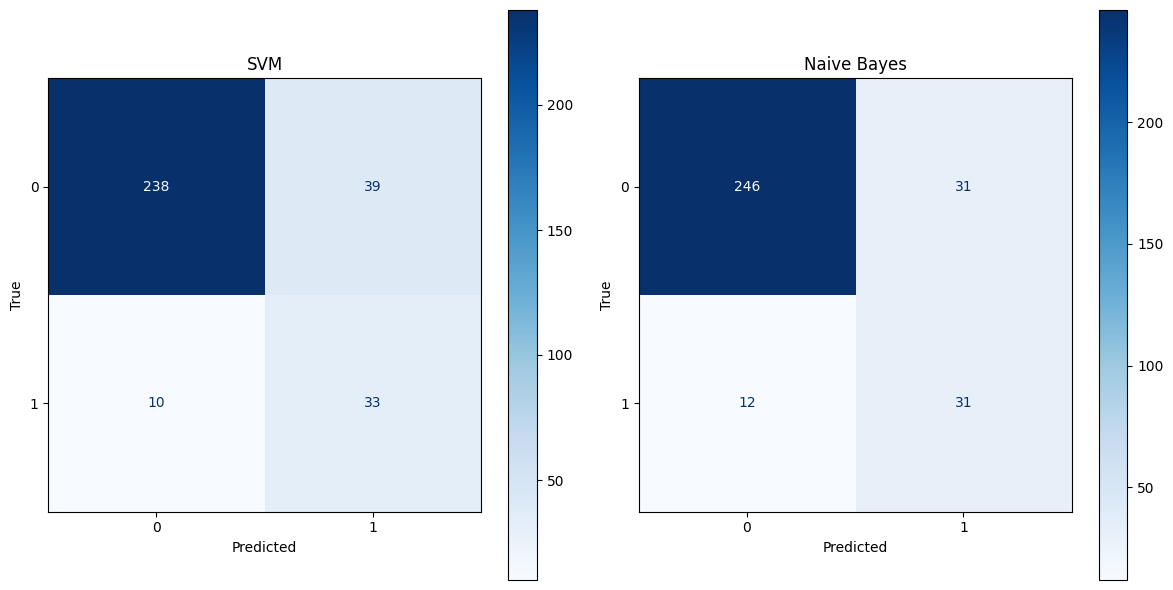

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for ax, pred, title in zip(axes, [pred_svm, pred_nb_gaussian], ['SVM', 'Naive Bayes']):
    cm = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
    disp.plot(cmap='Blues', ax=ax, values_format='d')
    ax.set_title(title)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')

plt.tight_layout()
plt.show()

**Interpretasi :**

- Tingkat Ketepatan Menyaring Sampel Kualitas Buruk (True Negative):

  - Kedua model sangat handal mengenali sampel wine yang mutunya rendah.
  - SVM sukses mendeteksi 238 sampel buruk, sementara Naive Bayes sedikit lebih unggul di angka 246 sampel.   

- Tingkat Deteksi Sampel Kualitas Baik (True Positive):
  - Dalam menangkap sampel wine yang benar-benar berkualitas tinggi, performanya masih terbatas.
  - SVM berhasil mendeteksi 33 sampel, sedangkan Naive Bayes menangkap 31 sampel.   

- Tingkat Salah Deteksi (False Alarm):
  - False Positive (Sampel buruk tapi dikira baik): SVM melakukan kesalahan pada 39 sampel, sedangkan Naive Bayes pada 31 sampel.   
  - False Negative (Sampel baik tapi dikira buruk): SVM melewatkan 10 sampel, sedangkan Naive Bayes melewatkan 12 sampel.

Kesimpulan untuk Stakeholder :
  - Kedua model sudah cukup baik untuk menyaring data sampel wine yang berkualitas rendah, namun masih memiliki risiko "kecolongan" (false negatives) yang cukup tinggi pada kelompok sampel wine bagus yang tidak terdeteksi.
  - Jika ingin dipakai untuk otomatisasi penilaian uji laboratorium, model perlu ditingkatkan lagi kinerjanya pada kelas positif agar tidak ada sampel unggulan yang salah diklasifikasikan.



### B) Classification Report - SVM

In [51]:
print(classification_report(y_test, pred_svm,
      target_names=["Tidak Baik", "Baik"]))

              precision    recall  f1-score   support

  Tidak Baik       0.96      0.86      0.91       277
        Baik       0.46      0.77      0.57        43

    accuracy                           0.85       320
   macro avg       0.71      0.81      0.74       320
weighted avg       0.89      0.85      0.86       320



**Interpretasi :**

- Akurasi Keseluruhan (85%):
  - Secara total, model berhasil melakukan prediksi dengan benar pada 85% dari keseluruhan sampel data uji (272 dari 320 sampel).

- Performa pada Kategori "Tidak Baik" (Mayoritas / 277 sampel):
  - Sangat Tinggi & Andal. Model memiliki tingkat ketepatan (precision) 96% dan tingkat deteksi (recall) 86%.
  - Artinya, saat model menyatakan suatu sampel wine itu "Tidak Baik", kita bisa sangat percaya, dan sebagian besar wine berkualitas rendah berhasil disaring dengan baik.

- Performa pada Kategori "Baik" (Minoritas / 43 sampel):
  - Cukup Sensitif tapi Kurang Presisi. Model berhasil mendeteksi 77% dari total wine yang aslinya berkualitas baik (recall 0.77).
  - Namun, tingkat ketepatannya rendah (presisi 0.46), yang berarti banyak sampel wine biasa/kurang yang keliru dikira sebagai wine berkualitas tinggi (False Positive).

Kesimpulan untuk Stakeholder:

  - Model SVM ini sangat handal dan aman dalam menyaring produk wine berkualitas rendah (risiko produk buruk lolos sangat kecil). Namun, karena presisi untuk kelas "Baik" masih rendah, model sering "salah duga" mengira wine biasa sebagai wine bagus.
  - Jika ingin dipakai untuk kontrol kualitas otomatis, model ini sangat bagus untuk screening awal produk jelek, tetapi perlu perbaikan agar produk unggulan tidak keliru diidentifikasi

### C) Classification Report - Naive Bayes

In [52]:
print(classification_report(y_test, pred_nb_gaussian,
      target_names=["Tidak Baik", "Baik"]))

              precision    recall  f1-score   support

  Tidak Baik       0.95      0.89      0.92       277
        Baik       0.50      0.72      0.59        43

    accuracy                           0.87       320
   macro avg       0.73      0.80      0.76       320
weighted avg       0.89      0.87      0.88       320



**Interpretasi :**

- Akurasi Keseluruhan (87%):
  - Secara total, model berhasil melakukan prediksi dengan benar pada 87% dari keseluruhan sampel data uji (278 dari 320 sampel).

- Performa pada Kategori "Tidak Baik" (277 sampel):
  - Sangat Kuat & Konsisten.
  - Model memiliki tingkat ketepatan (precision) 95% dan tingkat deteksi (recall) 89%.
  - Ini berarti model sangat handal dan akurat dalam menyaring sampel wine yang mutunya rendah tanpa banyak kecolongan.

- Performa pada Kategori "Baik" (43 sampel):
  - Cukup Baik namun Ada Catatan.
  - Model berhasil mendeteksi 72% dari total wine yang aslinya berkualitas baik (recall 0.59–0.72).
  - Namun, tingkat ketepatannya berada di angka 50% (precision 0.50), artinya separuh dari prediksi "Baik" yang dikeluarkan model sebenarnya adalah wine biasa/kurang.

Kesimpulan untuk Stakeholder:

- Dibandingkan model sebelumnya, Naive Bayes memberikan peningkatan akurasi keseluruhan yang sedikit lebih baik (87%) serta keseimbangan presisi yang lebih baik pada kategori wine bagus.
- Model ini sangat efektif untuk menyaring produk berkualitas rendah secara andal, meskipun masih ada sedikit ruang untuk menaikkan ketepatan pada kategori wine unggulan.

### Ringkasan Perbandingan Kedua Model


In [54]:
# Get dictionary classification reports
report_svm = classification_report(y_test, pred_svm, target_names=["Tidak Baik", "Baik"], output_dict=True)
report_nb = classification_report(y_test, pred_nb_gaussian, target_names=["Tidak Baik", "Baik"], output_dict=True)

# Construct summary DataFrame
result = pd.DataFrame({
    'Model': ['SVM', 'Naive Bayes'],
    'Akurasi': [
        accuracy_score(y_test, pred_svm),
        accuracy_score(y_test, pred_nb_gaussian)
    ],
    'Presisi Baik': [
        report_svm['Baik']['precision'],
        report_nb['Baik']['precision']
    ],
    'Presisi Buruk': [
        report_svm['Tidak Baik']['precision'],
        report_nb['Tidak Baik']['precision']
    ],
    'Recall Baik': [
        report_svm['Baik']['recall'],
        report_nb['Baik']['recall']
    ],
    'Recall Buruk': [
        report_svm['Tidak Baik']['recall'],
        report_nb['Tidak Baik']['recall']
    ]
})

result

,Model,Akurasi,Presisi Baik,Presisi Buruk,Recall Baik,Recall Buruk
0,SVM,0.846875,0.458333,0.959677,0.767442,0.859206
1,Naive Bayes,0.865625,0.500000,0.953488,0.720930,0.888087


Rekomendasi Model Terbaik:

Naive Bayes

 - Alasan Pemilihan (Perspektif Bisnis/C-Level):
    - Akurasi Keseluruhan Lebih Tinggi: Naive Bayes unggul dengan akurasi 86.56% (dibandingkan SVM yang berada di angka 84.69%).
    - Artinya, secara total persentase tebakan yang benar lebih banyak pada Naive Bayes.

- Ketepatan Kategori "Baik" (Precision Baik) Lebih Baik:
    - Naive Bayes memiliki presisi sebesar 50%, yang berarti dari setiap dua prediksi wine "Baik" yang dikeluarkan model, satu benar-benar berkualitas baik.
    - Sedangkan SVM lebih rendah di angka 45.8%, yang berisiko lebih tinggi salah mendeteksi wine biasa sebagai wine bagus.

- Kestabilan Kualitas Buruk:
    - Kedua model sama-sama sangat tangguh dalam mendeteksi wine tidak baik (memiliki presisi di kisaran 95%),
    - namun Naive Bayes memberikan keseimbangan metrik (macro/weighted average) yang lebih stabil secara keseluruhan.

Kesimpulan:
- Naive Bayes adalah pilihan terbaik karena memberikan tingkat akurasi yang lebih tinggi serta meminimalkan kesalahan deteksi pada produk unggulan dibandingkan SVM.

### 🌟 Kesimpulan Utama & Insight Strategis

Setelah melakukan eksperimen pemodelan menggunakan **Support Vector Machine (SVM)** dan **Naive Bayes** untuk memprediksi kualitas *red wine*, berikut adalah beberapa poin penting yang dapat dirangkum:

#### 1. Perbandingan Performa Model
- **Akurasi & Keseimbangan**: **Naive Bayes** keluar sebagai model terbaik dengan akurasi **86.56%** dan tingkat presisi untuk kelas *Baik* mencapai **50.00%** (lebih tinggi dibandingkan SVM yang hanya 45.83%).
- **Sensitivitas (Recall)**: **SVM** sedikit lebih unggul dalam mendeteksi wine berkualitas baik (**76.74%** banding **72.09%**), namun rentan memberikan *false alarm* (menebak wine biasa sebagai kualitas tinggi).

#### 2. Karakteristik Data (Insight Kimiawi)
- **Kadar Alkohol**: Berdasarkan analisis visual, kadar alkohol merupakan fitur yang paling berkorelasi positif dengan kualitas wine. Wine berkualitas tinggi rata-rata memiliki kadar alkohol yang lebih tinggi.
- **Volatile Acidity**: Tingkat keasaman yang mudah menguap berkorelasi negatif kuat dengan kualitas. Semakin tinggi keasaman ini, citarasa wine cenderung dinilai lebih rendah oleh penguji.
- **Imbalance Dataset**: Tantangan terbesar dalam data ini adalah ketidakseimbangan kelas, di mana hanya **13.6%** sampel yang tergolong berkualitas baik. Hal ini menjelaskan mengapa presisi untuk kelas positif (Baik) masih perlu ditingkatkan lagi.

---

### 🚀 Langkah Strategis Selanjutnya (Next Steps)
Jika proyek ini ingin diimplementasikan ke sistem otomatisasi kontrol kualitas (*Quality Control*) di pabrik, beberapa langkah ini sangat direkomendasikan:
1. **Penanganan Data Imbalance**: Mencoba teknik *oversampling* seperti **SMOTE** atau menyetel ulang batas probabilitas (*threshold tuning*) untuk menyeimbangkan nilai Presisi dan Recall pada kelas "Baik".
2. **Feature Engineering**: Membuat fitur baru dari kombinasi tingkat keasaman (misal rasio *fixed acidity* terhadap *volatile acidity*) guna membantu model memahami profil rasa secara lebih kompleks.
3. **Mencoba Algoritma Lain**: Mencoba model berbasis pohon keputusan seperti *Random Forest* atau *XGBoost* yang biasanya sangat tangguh dalam menangani data tabular dengan hubungan fitur non-linear.